In [1]:
# この部分はGPT4oの出力では無い。
import os

IMAGE_DIR = "image_executed"
SOURCE_IMG_DIR = "cropped_64x64"
# SOURCE_IMG_DIR = "cropped_64x64_permil10"
img_filename = os.path.join(SOURCE_IMG_DIR, "223_48_1.png")


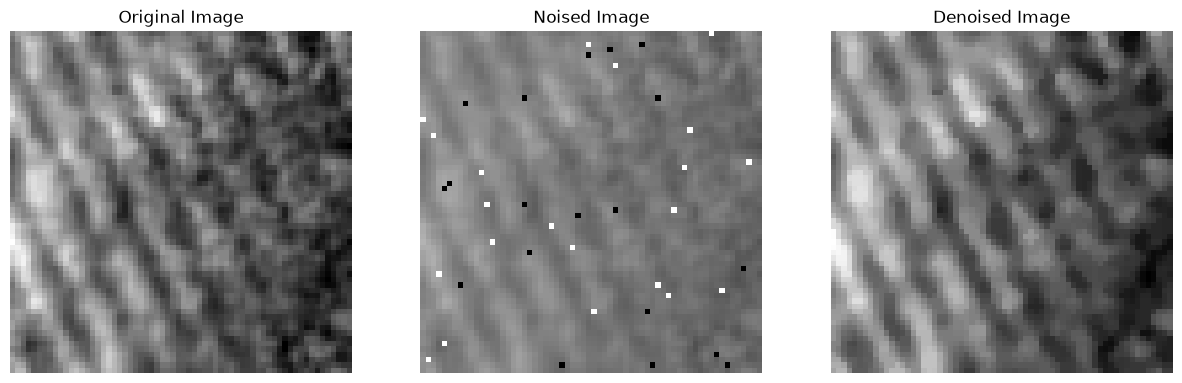

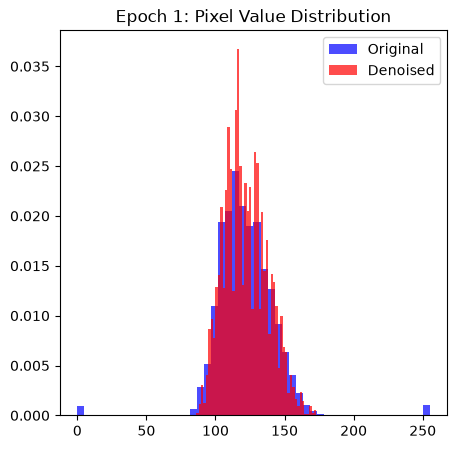

Images displayed.


In [2]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter

def plot_histograms(img, denoised_img, epoch):
    import os
    os.makedirs(IMAGE_DIR, exist_ok=True)
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    ax.hist(img.flatten(), bins=50, color='blue', alpha=0.7, label='Original', density=True)
    ax.hist(denoised_img.flatten(), bins=50, color='red', alpha=0.7, label='Denoised', density=True)
    ax.set_title(f'Epoch {epoch+1}: Pixel Value Distribution')
    ax.legend()
    plt.savefig(os.path.join(IMAGE_DIR, f"median_filtered.png"))
    plt.show()
    
def add_noise_and_display(img_filename, ratio):
    # 画像を読み込む
    img = Image.open(img_filename).convert('L')
    img_array = np.array(img)
    
    # 画像の次元サイズを取得
    height, width = img_array.shape
    
    # ノイズを付加するピクセル数を計算
    num_noisy_pixels = int(height * width * ratio)
    
    # ランダムなピクセル位置を生成
    noisy_indices = np.random.choice(height * width, num_noisy_pixels, replace=False)
    
    # 元の画像を平坦化
    flat_img = img_array.flatten()
    
    # ノイズを追加
    flat_img[noisy_indices] = np.random.choice([0, 255], num_noisy_pixels)
    
    # 改めて画像の形状に戻す
    noised_img_array = flat_img.reshape(height, width)
    
    # メディアンフィルタを適用してノイズを除去
    denoised_img_array = median_filter(noised_img_array, size=3)
    
    # 画像を並べて表示
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_array, cmap='gray')
    axes[0].set_title('Original Image')
    axes[0].axis('off')
    
    axes[1].imshow(noised_img_array, cmap='gray')
    axes[1].set_title('Noised Image')
    axes[1].axis('off')
    
    axes[2].imshow(denoised_img_array, cmap='gray')
    axes[2].set_title('Denoised Image')
    axes[2].axis('off')
    
    plt.show()

    plot_histograms(noised_img_array, denoised_img_array, 0)

    print("Images displayed.")

# 使用例
ratio = 0.01  # 10%のピクセルにノイズを追加

add_noise_and_display(img_filename, ratio)


詳細が異なるが，多くの場合に十分なデノイズを行うと思う．